In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the project root by locating the data file
CURRENT_FOLDER = Path.cwd()

PROJECT_ROOT = None

for folder in [CURRENT_FOLDER, *CURRENT_FOLDER.parents]:
    if (folder / "data" / "CAS_Data_public.csv").exists():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/CAS_Data_public.csv"
    )

CAS_PATH = PROJECT_ROOT / "data" / "CAS_Data_public.csv"

print("Current folder:", CURRENT_FOLDER)
print("Project folder:", PROJECT_ROOT)
print("CAS file:", CAS_PATH)
print("File exists:", CAS_PATH.exists())

Current folder: C:\Users\ASUS\Desktop\Project_Roadcrash\Notebook
Project folder: C:\Users\ASUS\Desktop\Project_Roadcrash
CAS file: C:\Users\ASUS\Desktop\Project_Roadcrash\data\CAS_Data_public.csv
File exists: True


In [2]:
# Load the first 5,000 rows for a quick check
sample_df = pd.read_csv(
    CAS_PATH,
    nrows=5000,
    low_memory=False
)

print("Sample rows and columns:", sample_df.shape)
print("\nFirst 5 rows:")
display(sample_df.head())

Sample rows and columns: (5000, 72)

First 5 rows:


,X,Y,OBJECTID,advisorySpeed,areaUnitID,bicycle,bridge,bus,carStationWagon,cliffBank,...,train,tree,truck,unknownVehicleType,urban,vanOrUtility,vehicle,waterRiver,weatherA,weatherB
0,1.764525e+06,5.912700e+06,1,NaN,520500.0,0,NaN,0,2,NaN,...,NaN,NaN,0,0,Urban,0,NaN,NaN,Light rain,Null
1,1.841709e+06,5.793399e+06,2,NaN,535250.0,0,0.0,0,1,0.0,...,0.0,1.0,0,0,Urban,1,0.0,0.0,Heavy rain,Strong wind
2,1.867074e+06,5.713159e+06,3,NaN,541720.0,0,NaN,0,1,NaN,...,NaN,NaN,0,0,Urban,1,NaN,NaN,Light rain,Null
3,1.751853e+06,5.435508e+06,4,NaN,573801.0,0,NaN,0,1,NaN,...,NaN,NaN,0,0,Open,0,NaN,NaN,Heavy rain,Null
4,1.723464e+06,6.041477e+06,5,NaN,504100.0,0,NaN,0,1,NaN,...,NaN,NaN,0,0,Urban,1,NaN,NaN,Fine,Null


In [3]:
print("Total number of columns:", len(sample_df.columns))

print("\nColumn names:")
for number, column in enumerate(sample_df.columns, start=1):
    print(f"{number}. {column}")

Total number of columns: 72

Column names:
1. X
2. Y
3. OBJECTID
4. advisorySpeed
5. areaUnitID
6. bicycle
7. bridge
8. bus
9. carStationWagon
10. cliffBank
11. crashDirectionDescription
12. crashFinancialYear
13. crashLocation1
14. crashLocation2
15. crashRoadSideRoad
16. crashSeverity
17. crashSHDescription
18. crashYear
19. debris
20. directionRoleDescription
21. ditch
22. fatalCount
23. fence
24. flatHill
25. guardRail
26. holiday
27. houseOrBuilding
28. intersection
29. kerb
30. light
31. meshblockId
32. minorInjuryCount
33. moped
34. motorcycle
35. NumberOfLanes
36. objectThrownOrDropped
37. otherObject
38. otherVehicleType
39. overBank
40. parkedVehicle
41. pedestrian
42. phoneBoxEtc
43. postOrPole
44. region
45. roadCharacter
46. roadLane
47. roadSurface
48. roadworks
49. schoolBus
50. seriousInjuryCount
51. slipOrFlood
52. speedLimit
53. strayAnimal
54. streetLight
55. suv
56. taxi
57. temporarySpeedLimit
58. tlaId
59. tlaName
60. trafficControl
61. trafficIsland
62. trafficSi

In [4]:
TARGET = "crashSeverity"

print("Crash severity values:")
print(sample_df[TARGET].value_counts(dropna=False))

print("\nPercentage distribution:")
print(
    sample_df[TARGET]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Crash severity values:
crashSeverity
Non-Injury Crash    3268
Minor Crash         1353
Serious Crash        334
Fatal Crash           45
Name: count, dtype: int64

Percentage distribution:
crashSeverity
Non-Injury Crash    65.36
Minor Crash         27.06
Serious Crash        6.68
Fatal Crash          0.90
Name: proportion, dtype: float64


In [5]:
leakage_columns = [
    "fatalCount",
    "seriousInjuryCount",
    "minorInjuryCount"
]

sample_df[
    [TARGET] + leakage_columns
].groupby(TARGET, dropna=False).agg(
    ["count", "mean", "min", "max"]
)


fatalCount                   seriousInjuryCount            \
                      count      mean min max              count      mean   
crashSeverity                                                                
Fatal Crash              45  1.044444   1   2                 45  0.444444   
Minor Crash            1353  0.000000   0   0               1353  0.000000   
Non-Injury Crash       3268  0.000000   0   0               3268  0.000000   
Serious Crash           334  0.000000   0   0                334  1.149701   

                         minorInjuryCount                    
                 min max            count      mean min max  
crashSeverity                                                
Fatal Crash        0   3               45  0.311111   0   3  
Minor Crash        0   0             1353  1.241685   1   7  
Non-Injury Crash   0   0             3268  0.000918   0   1  
Serious Crash      1   5              334  0.422156   0   6

In [6]:
# Load the complete CAS dataset
df = pd.read_csv(
    CAS_PATH,
    low_memory=False
)

print("Full dataset shape:", df.shape)
print(f"Total records: {len(df):,}")
print(f"Total columns: {df.shape[1]}")

Full dataset shape: (34866, 72)
Total records: 34,866
Total columns: 72


In [7]:
target_counts = df["crashSeverity"].value_counts(dropna=False)

target_percentages = (
    df["crashSeverity"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

,Count,Percentage
crashSeverity,,
Non-Injury Crash,22036,63.20
Minor Crash,9997,28.67
Serious Crash,2506,7.19
Fatal Crash,327,0.94


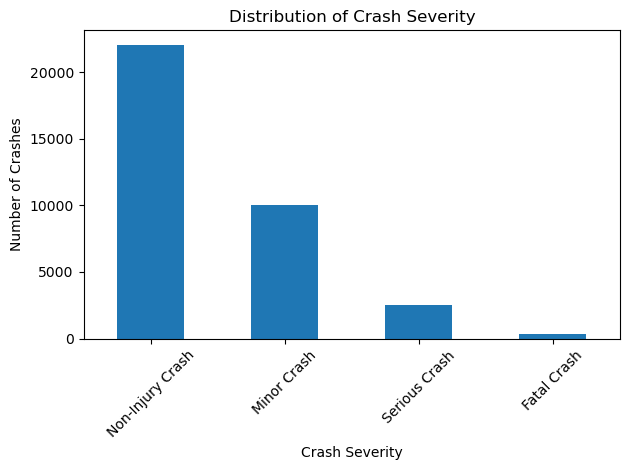

In [8]:
import matplotlib.pyplot as plt

target_counts.plot(kind="bar")

plt.title("Distribution of Crash Severity")
plt.xlabel("Crash Severity")
plt.ylabel("Number of Crashes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
TARGET_COLUMN = "crashSeverity"

LEAKAGE_COLUMNS = [
    "fatalCount",
    "seriousInjuryCount",
    "minorInjuryCount"
]

IDENTIFIER_COLUMNS = [
    "OBJECTID"
]

print("Target:", TARGET_COLUMN)
print("Leakage columns:", LEAKAGE_COLUMNS)
print("Identifier columns:", IDENTIFIER_COLUMNS)

Target: crashSeverity
Leakage columns: ['fatalCount', 'seriousInjuryCount', 'minorInjuryCount']
Identifier columns: ['OBJECTID']


In [10]:
print("Missing target values:", df[TARGET_COLUMN].isna().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget classes:")
print(df[TARGET_COLUMN].unique())

Missing target values: 0
Duplicate rows: 0

Target classes:
['Non-Injury Crash' 'Minor Crash' 'Serious Crash' 'Fatal Crash']


In [11]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_summary.head(25))

,Missing_Count,Missing_Percentage
crashRoadSideRoad,34866,100.00
intersection,34866,100.00
temporarySpeedLimit,33741,96.77
pedestrian,33292,95.49
advisorySpeed,33220,95.28
holiday,32963,94.54
otherObject,18503,53.07
ditch,18503,53.07
fence,18503,53.07
postOrPole,18503,53.07


In [12]:
completely_empty_columns = missing_summary[
    missing_summary["Missing_Percentage"] == 100
]

print("Completely empty columns:")
display(completely_empty_columns)

Completely empty columns:


,Missing_Count,Missing_Percentage
crashRoadSideRoad,34866,100.0
intersection,34866,100.0


In [13]:
data_type_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Values": [
        df[column].nunique(dropna=True)
        for column in df.columns
    ],
    "Missing_Percentage": [
        round(df[column].isna().mean() * 100, 2)
        for column in df.columns
    ]
})

display(data_type_summary)

,Column,Data_Type,Unique_Values,Missing_Percentage
0,X,float64,34862,0.00
1,Y,float64,34863,0.00
2,OBJECTID,int64,34866,0.00
3,advisorySpeed,float64,9,95.28
4,areaUnitID,float64,1794,0.40
...,...,...,...,...
67,vanOrUtility,int64,5,0.00
68,vehicle,float64,5,53.07
69,waterRiver,float64,2,53.07
70,weatherA,object,7,0.00


In [14]:
numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric columns:", len(numeric_columns))
print(numeric_columns)

print("\nCategorical columns:", len(categorical_columns))
print(categorical_columns)

Numeric columns: 52
['X', 'Y', 'OBJECTID', 'advisorySpeed', 'areaUnitID', 'bicycle', 'bridge', 'bus', 'carStationWagon', 'cliffBank', 'crashRoadSideRoad', 'crashYear', 'debris', 'ditch', 'fatalCount', 'fence', 'guardRail', 'houseOrBuilding', 'intersection', 'kerb', 'meshblockId', 'minorInjuryCount', 'moped', 'motorcycle', 'NumberOfLanes', 'objectThrownOrDropped', 'otherObject', 'otherVehicleType', 'overBank', 'parkedVehicle', 'pedestrian', 'phoneBoxEtc', 'postOrPole', 'roadworks', 'schoolBus', 'seriousInjuryCount', 'slipOrFlood', 'speedLimit', 'strayAnimal', 'suv', 'taxi', 'temporarySpeedLimit', 'tlaId', 'trafficIsland', 'trafficSign', 'train', 'tree', 'truck', 'unknownVehicleType', 'vanOrUtility', 'vehicle', 'waterRiver']

Categorical columns: 20
['crashDirectionDescription', 'crashFinancialYear', 'crashLocation1', 'crashLocation2', 'crashSeverity', 'crashSHDescription', 'directionRoleDescription', 'flatHill', 'holiday', 'light', 'region', 'roadCharacter', 'roadLane', 'roadSurface', '

In [15]:
for column in categorical_columns:
    print("\n" + "=" * 70)
    print("Column:", column)
    print("Unique values:", df[column].nunique(dropna=True))
    print(df[column].value_counts(dropna=False).head(15))


Column: crashDirectionDescription
Unique values: 5
crashDirectionDescription
Null     12567
South     7135
North     6744
West      4286
East      4134
Name: count, dtype: int64

Column: crashFinancialYear
Unique values: 2
crashFinancialYear
2025/2026    20286
2024/2025    14580
Name: count, dtype: int64

Column: crashLocation1
Unique values: 7504
crashLocation1
SH 1                      735
SOUTHERN MOTORWAY         703
SH 2                      479
GREAT SOUTH ROAD          432
NORTHERN MOTORWAY         390
SOUTH-WESTERN MOTORWAY    252
NORTH-WESTERN MOTORWAY    224
WAIKATO EXPRESSWAY        181
GREAT NORTH ROAD          167
SH 5                      153
HIGH STREET               140
SH 29                     138
MAIN SOUTH ROAD           131
SH 3                      131
MAIN ROAD                 106
Name: count, dtype: int64

Column: crashLocation2
Unique values: 13835
crashLocation2
NaN                  280
GREAT SOUTH ROAD     128
QUEEN STREET          66
GREY STREET           6

In [16]:
display(missing_summary.head(25))

,Missing_Count,Missing_Percentage
crashRoadSideRoad,34866,100.00
intersection,34866,100.00
temporarySpeedLimit,33741,96.77
pedestrian,33292,95.49
advisorySpeed,33220,95.28
holiday,32963,94.54
otherObject,18503,53.07
ditch,18503,53.07
fence,18503,53.07
postOrPole,18503,53.07


In [17]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing target values:", df[TARGET_COLUMN].isna().sum())

Duplicate rows: 0
Missing target values: 0


In [18]:
columns_53_missing = missing_summary[
    missing_summary["Missing_Percentage"].between(53.0, 53.1)
].index.tolist()

print("Columns with approximately 53.07% missing:")
print(columns_53_missing)

print("\nMissingness by financial year:")

for column in columns_53_missing:
    summary = (
        df.groupby("crashFinancialYear")[column]
        .apply(lambda x: x.isna().mean() * 100)
        .round(2)
    )

    print(f"\n{column}")
    print(summary)

Columns with approximately 53.07% missing:
['otherObject', 'ditch', 'fence', 'postOrPole', 'guardRail', 'houseOrBuilding', 'debris', 'kerb', 'phoneBoxEtc', 'parkedVehicle', 'overBank', 'roadworks', 'slipOrFlood', 'strayAnimal', 'trafficIsland', 'cliffBank', 'trafficSign', 'train', 'bridge', 'tree', 'vehicle', 'waterRiver', 'objectThrownOrDropped']

Missingness by financial year:

otherObject
crashFinancialYear
2024/2025    53.99
2025/2026    52.41
Name: otherObject, dtype: float64

ditch
crashFinancialYear
2024/2025    53.99
2025/2026    52.41
Name: ditch, dtype: float64

fence
crashFinancialYear
2024/2025    53.99
2025/2026    52.41
Name: fence, dtype: float64

postOrPole
crashFinancialYear
2024/2025    53.99
2025/2026    52.41
Name: postOrPole, dtype: float64

guardRail
crashFinancialYear
2024/2025    53.99
2025/2026    52.41
Name: guardRail, dtype: float64

houseOrBuilding
crashFinancialYear
2024/2025    53.99
2025/2026    52.41
Name: houseOrBuilding, dtype: float64

debris
crashFin

In [19]:
object_columns = [
    "otherObject", "ditch", "fence", "postOrPole",
    "guardRail", "houseOrBuilding", "debris", "kerb",
    "phoneBoxEtc", "parkedVehicle", "overBank",
    "roadworks", "slipOrFlood", "strayAnimal",
    "trafficIsland", "cliffBank", "trafficSign",
    "train", "bridge", "tree", "vehicle",
    "waterRiver", "objectThrownOrDropped"
]

for column in object_columns:
    print("\n" + "=" * 60)
    print("Column:", column)
    print(df[column].value_counts(dropna=False))


Column: otherObject
otherObject
NaN    18503
0.0    15960
1.0      396
2.0        6
5.0        1
Name: count, dtype: int64

Column: ditch
ditch
NaN    18503
0.0    14941
1.0     1408
2.0       13
3.0        1
Name: count, dtype: int64

Column: fence
fence
NaN    18503
0.0    13093
1.0     3152
2.0      116
3.0        2
Name: count, dtype: int64

Column: postOrPole
postOrPole
NaN    18503
0.0    14587
1.0     1746
2.0       29
3.0        1
Name: count, dtype: int64

Column: guardRail
guardRail
NaN    18503
0.0    14380
1.0     1919
2.0       64
Name: count, dtype: int64

Column: houseOrBuilding
houseOrBuilding
NaN    18503
0.0    16034
1.0      327
2.0        2
Name: count, dtype: int64

Column: debris
debris
NaN    18503
0.0    16193
1.0      164
2.0        4
6.0        1
3.0        1
Name: count, dtype: int64

Column: kerb
kerb
NaN    18503
0.0    15818
1.0      543
2.0        2
Name: count, dtype: int64

Column: phoneBoxEtc
phoneBoxEtc
NaN    18503
0.0    16128
1.0      228
2.0     

In [20]:
TARGET_COLUMN = "crashSeverity"

DIRECT_LEAKAGE_COLUMNS = [
    "fatalCount",
    "seriousInjuryCount",
    "minorInjuryCount"
]

IDENTIFIER_COLUMNS = [
    "OBJECTID"
]

EMPTY_COLUMNS = [
    "crashRoadSideRoad",
    "intersection"
]

POST_CRASH_OBJECT_COLUMNS = [
    "otherObject", "ditch", "fence", "postOrPole",
    "guardRail", "houseOrBuilding", "debris", "kerb",
    "phoneBoxEtc", "parkedVehicle", "overBank",
    "roadworks", "slipOrFlood", "strayAnimal",
    "trafficIsland", "cliffBank", "trafficSign",
    "train", "bridge", "tree", "vehicle",
    "waterRiver", "objectThrownOrDropped"
]

columns_to_exclude = (
    DIRECT_LEAKAGE_COLUMNS
    + IDENTIFIER_COLUMNS
    + EMPTY_COLUMNS
    + POST_CRASH_OBJECT_COLUMNS
)

model_df = df.drop(columns=columns_to_exclude).copy()

print("Original dataset:", df.shape)
print("Baseline modelling dataset:", model_df.shape)

print("\nExcluded columns:", len(columns_to_exclude))
for col in columns_to_exclude:
    print("-", col)

Original dataset: (34866, 72)
Baseline modelling dataset: (34866, 43)

Excluded columns: 29
- fatalCount
- seriousInjuryCount
- minorInjuryCount
- OBJECTID
- crashRoadSideRoad
- intersection
- otherObject
- ditch
- fence
- postOrPole
- guardRail
- houseOrBuilding
- debris
- kerb
- phoneBoxEtc
- parkedVehicle
- overBank
- roadworks
- slipOrFlood
- strayAnimal
- trafficIsland
- cliffBank
- trafficSign
- train
- bridge
- tree
- vehicle
- waterRiver
- objectThrownOrDropped


In [21]:
remaining_missing = pd.DataFrame({
    "Missing_Count": model_df.isna().sum(),
    "Missing_Percentage": (
        model_df.isna().mean() * 100
    ).round(2)
})

remaining_missing = remaining_missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(remaining_missing.head(20))

,Missing_Count,Missing_Percentage
temporarySpeedLimit,33741,96.77
pedestrian,33292,95.49
advisorySpeed,33220,95.28
holiday,32963,94.54
streetLight,9704,27.83
region,291,0.83
crashLocation2,280,0.80
speedLimit,259,0.74
NumberOfLanes,188,0.54
weatherB,142,0.41


In [22]:
feature_summary = pd.DataFrame({
    "Column": model_df.columns,
    "Data_Type": model_df.dtypes.astype(str).values,
    "Unique_Values": [
        model_df[col].nunique(dropna=True)
        for col in model_df.columns
    ],
    "Missing_Percentage": [
        round(model_df[col].isna().mean() * 100, 2)
        for col in model_df.columns
    ]
})

feature_summary = feature_summary.sort_values(
    "Unique_Values"
)

display(feature_summary)

,Column,Data_Type,Unique_Values,Missing_Percentage
39,urban,object,2,0.00
13,crashYear,int64,2,0.00
8,crashFinancialYear,object,2,0.00
42,weatherB,object,3,0.41
30,streetLight,object,3,27.83
22,otherVehicleType,int64,3,0.00
19,moped,int64,3,0.00
15,flatHill,object,3,0.00
12,crashSHDescription,object,3,0.40
28,schoolBus,int64,3,0.00


In [23]:
high_missing_columns = [
    "temporarySpeedLimit",
    "pedestrian",
    "advisorySpeed",
    "holiday"
]

for column in high_missing_columns:
    print("\n" + "=" * 60)
    print("Column:", column)
    print("Data type:", df[column].dtype)
    print("Unique non-null values:", df[column].nunique(dropna=True))
    print(df[column].value_counts(dropna=False).head(30))


Column: temporarySpeedLimit
Data type: float64
Unique non-null values: 9
temporarySpeedLimit
NaN     33741
30.0      523
40.0      188
50.0      183
60.0       58
70.0       48
80.0       48
20.0       40
10.0       19
90.0       18
Name: count, dtype: int64

Column: pedestrian
Data type: float64
Unique non-null values: 5
pedestrian
NaN    33292
1.0     1453
2.0       93
3.0       22
4.0        5
5.0        1
Name: count, dtype: int64

Column: advisorySpeed
Data type: float64
Unique non-null values: 9
advisorySpeed
NaN     33220
45.0      350
35.0      305
55.0      269
65.0      247
75.0      210
25.0      108
85.0      107
15.0       25
95.0       25
Name: count, dtype: int64

Column: holiday
Data type: object
Unique non-null values: 4
holiday
NaN                   32963
Christmas New Year     1008
Easter                  347
Queens Birthday         287
Labour Weekend          261
Name: count, dtype: int64


In [24]:
location_columns = [
    "crashLocation1",
    "crashLocation2",
    "meshblockId",
    "areaUnitID",
    "tlaId",
    "tlaName",
    "region",
    "crashSHDescription"
]

for column in location_columns:
    print(
        f"{column}: "
        f"{df[column].nunique(dropna=True)} unique values"
    )

crashLocation1: 7504 unique values
crashLocation2: 13835 unique values
meshblockId: 15580 unique values
areaUnitID: 1794 unique values
tlaId: 67 unique values
tlaName: 67 unique values
region: 16 unique values
crashSHDescription: 3 unique values


In [25]:
high_missing_columns = [
    "temporarySpeedLimit",
    "pedestrian",
    "advisorySpeed",
    "holiday"
]

for column in high_missing_columns:
    print("\n" + "=" * 60)
    print("Column:", column)
    print("Data type:", df[column].dtype)
    print("Unique non-null values:", df[column].nunique(dropna=True))
    print(df[column].value_counts(dropna=False))


Column: temporarySpeedLimit
Data type: float64
Unique non-null values: 9
temporarySpeedLimit
NaN     33741
30.0      523
40.0      188
50.0      183
60.0       58
70.0       48
80.0       48
20.0       40
10.0       19
90.0       18
Name: count, dtype: int64

Column: pedestrian
Data type: float64
Unique non-null values: 5
pedestrian
NaN    33292
1.0     1453
2.0       93
3.0       22
4.0        5
5.0        1
Name: count, dtype: int64

Column: advisorySpeed
Data type: float64
Unique non-null values: 9
advisorySpeed
NaN     33220
45.0      350
35.0      305
55.0      269
65.0      247
75.0      210
25.0      108
85.0      107
15.0       25
95.0       25
Name: count, dtype: int64

Column: holiday
Data type: object
Unique non-null values: 4
holiday
NaN                   32963
Christmas New Year     1008
Easter                  347
Queens Birthday         287
Labour Weekend          261
Name: count, dtype: int64


In [26]:
BASELINE_LOCATION_EXCLUDE = [
    "crashLocation1",
    "crashLocation2",
    "meshblockId",
    "areaUnitID",
    "tlaId",
    "tlaName",
    "X",
    "Y"
]

baseline_df = model_df.drop(
    columns=BASELINE_LOCATION_EXCLUDE
).copy()

print("Current modelling dataset:", model_df.shape)
print("Baseline dataset:", baseline_df.shape)

print("\nRemaining columns:")
for column in baseline_df.columns:
    print(column)

Current modelling dataset: (34866, 43)
Baseline dataset: (34866, 35)

Remaining columns:
advisorySpeed
bicycle
bus
carStationWagon
crashDirectionDescription
crashFinancialYear
crashSeverity
crashSHDescription
crashYear
directionRoleDescription
flatHill
holiday
light
moped
motorcycle
NumberOfLanes
otherVehicleType
pedestrian
region
roadCharacter
roadLane
roadSurface
schoolBus
speedLimit
streetLight
suv
taxi
temporarySpeedLimit
trafficControl
truck
unknownVehicleType
urban
vanOrUtility
weatherA
weatherB


In [27]:
feature_audit = pd.DataFrame({
    "Column": baseline_df.columns,
    "Data_Type": baseline_df.dtypes.astype(str).values,
    "Unique_Values": [
        baseline_df[col].nunique(dropna=True)
        for col in baseline_df.columns
    ],
    "Missing_Count": [
        baseline_df[col].isna().sum()
        for col in baseline_df.columns
    ],
    "Missing_Percentage": [
        round(baseline_df[col].isna().mean() * 100, 2)
        for col in baseline_df.columns
    ]
})

display(feature_audit)

,Column,Data_Type,Unique_Values,Missing_Count,Missing_Percentage
0,advisorySpeed,float64,9,33220,95.28
1,bicycle,int64,5,0,0.00
2,bus,int64,3,0,0.00
3,carStationWagon,int64,10,0,0.00
4,crashDirectionDescription,object,5,0,0.00
5,crashFinancialYear,object,2,0,0.00
6,crashSeverity,object,4,0,0.00
7,crashSHDescription,object,3,138,0.40
8,crashYear,int64,2,0,0.00
9,directionRoleDescription,object,5,0,0.00


In [28]:
categorical_cols = baseline_df.select_dtypes(
    exclude=["number"]
).columns.tolist()

for column in categorical_cols:
    print("\n" + "=" * 60)
    print("Column:", column)
    print("Unique values:", baseline_df[column].nunique(dropna=True))
    print(baseline_df[column].value_counts(dropna=False).head(20))


Column: crashDirectionDescription
Unique values: 5
crashDirectionDescription
Null     12567
South     7135
North     6744
West      4286
East      4134
Name: count, dtype: int64

Column: crashFinancialYear
Unique values: 2
crashFinancialYear
2025/2026    20286
2024/2025    14580
Name: count, dtype: int64

Column: crashSeverity
Unique values: 4
crashSeverity
Non-Injury Crash    22036
Minor Crash          9997
Serious Crash        2506
Fatal Crash           327
Name: count, dtype: int64

Column: crashSHDescription
Unique values: 3
crashSHDescription
No         24294
Yes        10416
NaN          138
Unknown       18
Name: count, dtype: int64

Column: directionRoleDescription
Unique values: 5
directionRoleDescription
North    11475
South    10926
East      6266
West      6070
Null       129
Name: count, dtype: int64

Column: flatHill
Unique values: 3
flatHill
Flat         25945
Hill Road     6729
Null          2192
Name: count, dtype: int64

Column: holiday
Unique values: 4
holiday
NaN  

In [29]:
SPARSE_COLUMNS = [
    "advisorySpeed",
    "temporarySpeedLimit",
    "pedestrian",
    "holiday"
]

final_baseline_df = baseline_df.drop(
    columns=SPARSE_COLUMNS
).copy()

print("Before sparse-column removal:", baseline_df.shape)
print("Final baseline dataset:", final_baseline_df.shape)

print("\nPredictor count:",
      final_baseline_df.shape[1] - 1)

Before sparse-column removal: (34866, 35)
Final baseline dataset: (34866, 31)

Predictor count: 30


In [30]:
X = final_baseline_df.drop(
    columns=["crashSeverity"]
).copy()

y = final_baseline_df["crashSeverity"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

X shape: (34866, 30)
y shape: (34866,)

Target distribution:
crashSeverity
Non-Injury Crash    22036
Minor Crash          9997
Serious Crash        2506
Fatal Crash           327
Name: count, dtype: int64

Target percentage:
crashSeverity
Non-Injury Crash    63.20
Minor Crash         28.67
Serious Crash        7.19
Fatal Crash          0.94
Name: proportion, dtype: float64


In [31]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric predictors:", len(numeric_features))
print(numeric_features)

print("\nCategorical predictors:", len(categorical_features))
print(categorical_features)

Numeric predictors: 15
['bicycle', 'bus', 'carStationWagon', 'crashYear', 'moped', 'motorcycle', 'NumberOfLanes', 'otherVehicleType', 'schoolBus', 'speedLimit', 'suv', 'taxi', 'truck', 'unknownVehicleType', 'vanOrUtility']

Categorical predictors: 15
['crashDirectionDescription', 'crashFinancialYear', 'crashSHDescription', 'directionRoleDescription', 'flatHill', 'light', 'region', 'roadCharacter', 'roadLane', 'roadSurface', 'streetLight', 'trafficControl', 'urban', 'weatherA', 'weatherB']


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (27892, 30)
Testing data: (6974, 30)

Training target distribution:
crashSeverity
Non-Injury Crash    17628
Minor Crash          7997
Serious Crash        2005
Fatal Crash           262
Name: count, dtype: int64

Testing target distribution:
crashSeverity
Non-Injury Crash    4408
Minor Crash         2000
Serious Crash        501
Fatal Crash           65
Name: count, dtype: int64


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [34]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (27892, 94)
Processed testing shape: (6974, 94)


In [35]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train_processed,
    y_train
)

dummy_predictions = dummy_model.predict(
    X_test_processed
)

print("Dummy Classifier Results")
print("=" * 50)

print(
    "Accuracy:",
    round(accuracy_score(y_test, dummy_predictions), 4)
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            dummy_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            dummy_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        dummy_predictions,
        zero_division=0
    )
)

Dummy Classifier Results
Accuracy: 0.6321
Balanced Accuracy: 0.25
Macro F1: 0.1936

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash       0.00      0.00      0.00        65
     Minor Crash       0.00      0.00      0.00      2000
Non-Injury Crash       0.63      1.00      0.77      4408
   Serious Crash       0.00      0.00      0.00       501

        accuracy                           0.63      6974
       macro avg       0.16      0.25      0.19      6974
    weighted avg       0.40      0.63      0.49      6974



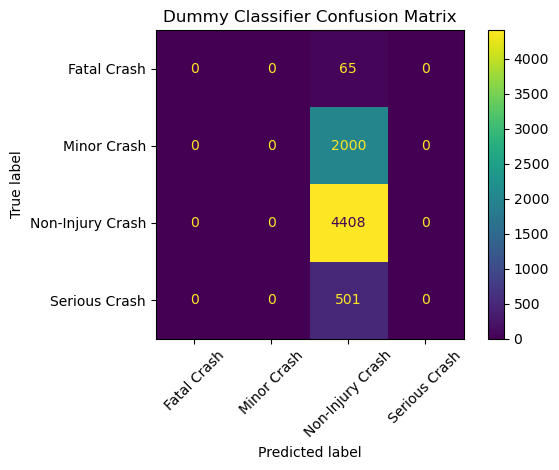

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dummy_predictions,
    xticks_rotation=45
)

plt.title("Dummy Classifier Confusion Matrix")
plt.tight_layout()
plt.show()

In [37]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

logistic_predictions = logistic_model.predict(
    X_test_processed
)

print("Logistic Regression Results")
print("=" * 50)

print(
    "Accuracy:",
    round(accuracy_score(y_test, logistic_predictions), 4)
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            logistic_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            logistic_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

Logistic Regression Results
Accuracy: 0.6709
Balanced Accuracy: 0.3012
Macro F1: 0.2918

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash       0.00      0.00      0.00        65
     Minor Crash       0.55      0.17      0.26      2000
Non-Injury Crash       0.68      0.98      0.81      4408
   Serious Crash       0.48      0.06      0.10       501

        accuracy                           0.67      6974
       macro avg       0.43      0.30      0.29      6974
    weighted avg       0.63      0.67      0.59      6974



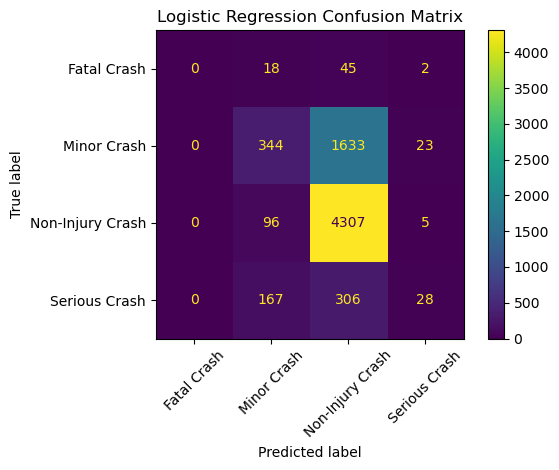

In [38]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    xticks_rotation=45
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [39]:
balanced_logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42,
    class_weight="balanced"
)

balanced_logistic_model.fit(
    X_train_processed,
    y_train
)

balanced_logistic_predictions = balanced_logistic_model.predict(
    X_test_processed
)

print("Balanced Logistic Regression Results")
print("=" * 50)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test,
            balanced_logistic_predictions
        ),
        4
    )
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            balanced_logistic_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            balanced_logistic_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        balanced_logistic_predictions,
        zero_division=0
    )
)

Balanced Logistic Regression Results
Accuracy: 0.4498
Balanced Accuracy: 0.4129
Macro F1: 0.3065

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash       0.02      0.49      0.05        65
     Minor Crash       0.34      0.28      0.30      2000
Non-Injury Crash       0.76      0.54      0.63      4408
   Serious Crash       0.19      0.34      0.24       501

        accuracy                           0.45      6974
       macro avg       0.33      0.41      0.31      6974
    weighted avg       0.59      0.45      0.50      6974



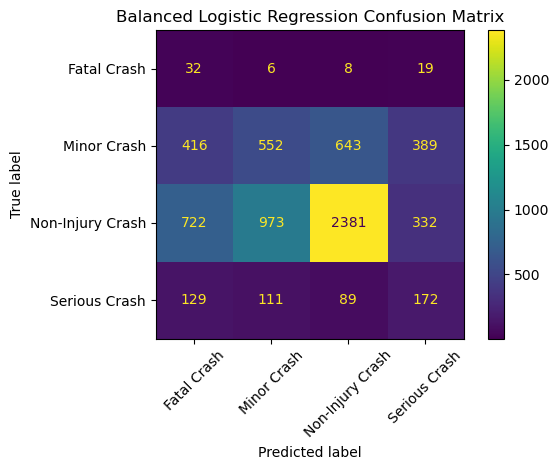

In [40]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    balanced_logistic_predictions,
    xticks_rotation=45
)

plt.title(
    "Balanced Logistic Regression Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [41]:
results_comparison = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(
            y_test,
            dummy_predictions
        ),
        accuracy_score(
            y_test,
            logistic_predictions
        ),
        accuracy_score(
            y_test,
            balanced_logistic_predictions
        )
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(
            y_test,
            dummy_predictions
        ),
        balanced_accuracy_score(
            y_test,
            logistic_predictions
        ),
        balanced_accuracy_score(
            y_test,
            balanced_logistic_predictions
        )
    ],
    "Macro F1": [
        f1_score(
            y_test,
            dummy_predictions,
            average="macro"
        ),
        f1_score(
            y_test,
            logistic_predictions,
            average="macro"
        ),
        f1_score(
            y_test,
            balanced_logistic_predictions,
            average="macro"
        )
    ]
})

display(
    results_comparison.round(4)
)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Dummy Classifier,0.6321,0.2500,0.1936
1,Logistic Regression,0.6709,0.3012,0.2918
2,Balanced Logistic Regression,0.4498,0.4129,0.3065


### Initial Class-Imbalance Finding

The standard Logistic Regression model achieved higher overall accuracy (67.09%) but performed poorly on minority severity classes. It detected no Fatal crashes and only 6% of Serious crashes.

Applying balanced class weights reduced overall accuracy to 44.98%, but increased balanced accuracy from 30.12% to 41.29%. Fatal-crash recall increased from 0% to 49%, while Serious-crash recall increased from 6% to 34%.

However, Fatal-crash precision remained very low (2%), indicating a large number of false-positive Fatal predictions. This demonstrates the trade-off between overall classification accuracy and minority-class sensitivity in the highly imbalanced CAS dataset.

In [42]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_processed,
    y_train
)

rf_predictions = random_forest_model.predict(
    X_test_processed
)

print("Random Forest Results")
print("=" * 50)

print(
    "Accuracy:",
    round(accuracy_score(y_test, rf_predictions), 4)
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            rf_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            rf_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

Random Forest Results
Accuracy: 0.6372
Balanced Accuracy: 0.3094
Macro F1: 0.3127

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash       0.00      0.00      0.00        65
     Minor Crash       0.42      0.25      0.32      2000
Non-Injury Crash       0.69      0.88      0.78      4408
   Serious Crash       0.36      0.10      0.16       501

        accuracy                           0.64      6974
       macro avg       0.37      0.31      0.31      6974
    weighted avg       0.58      0.64      0.59      6974



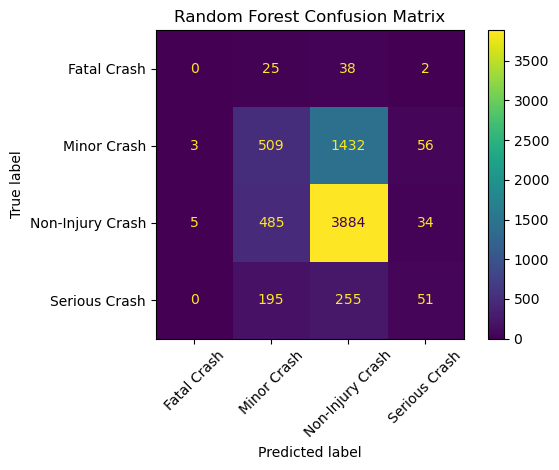

In [43]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    xticks_rotation=45
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

### Random Forest Baseline Finding

The standard Random Forest achieved an accuracy of 63.72%, balanced accuracy of 30.94%, and macro-F1 of 31.27%.

Although Random Forest improved the classification of Minor and Serious crashes compared with the standard Logistic Regression model, it failed to identify any Fatal crashes. The model remained biased towards the majority Non-Injury class, which achieved a recall of 88%.

This result further confirms that class imbalance is a major challenge in this dataset and that imbalance-handling techniques are required to improve minority-class detection.

In [44]:
balanced_rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

balanced_rf_model.fit(
    X_train_processed,
    y_train
)

balanced_rf_predictions = balanced_rf_model.predict(
    X_test_processed
)

print("Balanced Random Forest Results")
print("=" * 50)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test,
            balanced_rf_predictions
        ),
        4
    )
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            balanced_rf_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            balanced_rf_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        balanced_rf_predictions,
        zero_division=0
    )
)

Balanced Random Forest Results
Accuracy: 0.6291
Balanced Accuracy: 0.3042
Macro F1: 0.3053

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash       0.00      0.00      0.00        65
     Minor Crash       0.41      0.25      0.31      2000
Non-Injury Crash       0.69      0.87      0.77      4408
   Serious Crash       0.26      0.09      0.14       501

        accuracy                           0.63      6974
       macro avg       0.34      0.30      0.31      6974
    weighted avg       0.57      0.63      0.59      6974



### Effect of Class Weighting on Random Forest

Applying balanced class weights to the Random Forest did not improve minority-class performance. The balanced model achieved slightly lower accuracy, balanced accuracy, and macro-F1 than the standard Random Forest.

Most importantly, both Random Forest models failed to correctly identify any Fatal crashes. Serious-crash recall also decreased slightly from 10% to 9%.

This suggests that class weighting alone is insufficient for handling the severe class imbalance in the CAS dataset. Therefore, an alternative imbalance-handling strategy is required.

In [45]:
!pip install imbalanced-learn

In [46]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(
    random_state=42
)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_processed,
    y_train
)

print("Original training size:", X_train_processed.shape)
print("Oversampled training size:", X_train_ros.shape)

print("\nOriginal target distribution:")
print(y_train.value_counts())

print("\nOversampled target distribution:")
print(y_train_ros.value_counts())

Original training size: (27892, 94)
Oversampled training size: (70512, 94)

Original target distribution:
crashSeverity
Non-Injury Crash    17628
Minor Crash          7997
Serious Crash        2005
Fatal Crash           262
Name: count, dtype: int64

Oversampled target distribution:
crashSeverity
Non-Injury Crash    17628
Minor Crash         17628
Serious Crash       17628
Fatal Crash         17628
Name: count, dtype: int64


In [47]:
ros_logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

ros_logistic_model.fit(
    X_train_ros,
    y_train_ros
)

ros_logistic_predictions = ros_logistic_model.predict(
    X_test_processed
)

print("Oversampled Logistic Regression Results")
print("=" * 50)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test,
            ros_logistic_predictions
        ),
        4
    )
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            ros_logistic_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            ros_logistic_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        ros_logistic_predictions,
        zero_division=0
    )
)

Oversampled Logistic Regression Results
Accuracy: 0.4465
Balanced Accuracy: 0.4089
Macro F1: 0.3052

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash       0.02      0.48      0.05        65
     Minor Crash       0.34      0.28      0.31      2000
Non-Injury Crash       0.76      0.53      0.63      4408
   Serious Crash       0.18      0.34      0.24       501

        accuracy                           0.45      6974
       macro avg       0.33      0.41      0.31      6974
    weighted avg       0.59      0.45      0.50      6974



In [48]:
# Compare models using their predictions on the same held-out test set.

baseline_predictions = {
    "Dummy Classifier": dummy_predictions,
    "Logistic Regression": logistic_predictions,
    "Balanced Logistic Regression": balanced_logistic_predictions,
    "Random Forest": rf_predictions,
    "Balanced Random Forest": balanced_rf_predictions,
    "Oversampled Logistic Regression": ros_logistic_predictions
}

model_results = pd.DataFrame([
    {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )
    }
    for model_name, predictions in baseline_predictions.items()
])

display(model_results.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Dummy Classifier,0.6321,0.2500,0.1936
1,Logistic Regression,0.6709,0.3012,0.2918
2,Balanced Logistic Regression,0.4498,0.4129,0.3065
3,Random Forest,0.6372,0.3094,0.3127
4,Balanced Random Forest,0.6291,0.3042,0.3053
5,Oversampled Logistic Regression,0.4465,0.4089,0.3052


In [49]:
!pip install xgboost

In [50]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:")
for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)

Classes:
0 = Fatal Crash
1 = Minor Crash
2 = Non-Injury Crash
3 = Serious Crash


In [51]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train_encoded
)

xgb_predictions_encoded = xgb_model.predict(
    X_test_processed
)

xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded
)

print("XGBoost Results")

print(
    "Accuracy:",
    round(accuracy_score(y_test, xgb_predictions), 4)
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            xgb_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            xgb_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_predictions,
        zero_division=0
    )
)

XGBoost Results
Accuracy: 0.6703
Balanced Accuracy: 0.3079
Macro F1: 0.3034

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash       0.00      0.00      0.00        65
     Minor Crash       0.54      0.17      0.26      2000
Non-Injury Crash       0.69      0.97      0.80      4408
   Serious Crash       0.48      0.09      0.15       501

        accuracy                           0.67      6974
       macro avg       0.43      0.31      0.30      6974
    weighted avg       0.62      0.67      0.59      6974



### XGBoost Baseline Finding

The standard XGBoost model achieved 67.03% accuracy, 30.79% balanced accuracy, and a macro-F1 score of 30.34%.

Despite its relatively high overall accuracy, the model failed to identify any Fatal crashes and detected only 9% of Serious crashes. In contrast, it correctly classified 97% of Non-Injury crashes.

This explains that a strong overall accuracy score does not necessarily indicate good performance across all severity classes. The severe class imbalance continues to bias the model toward the majority Non-Injury class.

In [52]:
from sklearn.utils.class_weight import compute_sample_weight

xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)

print("Number of sample weights:", len(xgb_sample_weights))

print("\nWeight summary:")
print(pd.Series(xgb_sample_weights).describe())

Number of sample weights: 27892

Weight summary:
count    27892.000000
mean         1.000000
std          2.615378
min          0.395564
25%          0.395564
50%          0.395564
75%          0.871952
max         26.614504
dtype: float64


In [53]:
weighted_xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

weighted_xgb_model.fit(
    X_train_processed,
    y_train_encoded,
    sample_weight=xgb_sample_weights
)

weighted_xgb_predictions_encoded = weighted_xgb_model.predict(
    X_test_processed
)

weighted_xgb_predictions = label_encoder.inverse_transform(
    weighted_xgb_predictions_encoded
)

print("Weighted XGBoost Results")

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test,
            weighted_xgb_predictions
        ),
        4
    )
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test,
            weighted_xgb_predictions
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_test,
            weighted_xgb_predictions,
            average="macro"
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        weighted_xgb_predictions,
        zero_division=0
    )
)

Weighted XGBoost Results
Accuracy: 0.49
Balanced Accuracy: 0.4076
Macro F1: 0.3272

Classification Report:
                  precision    recall  f1-score   support

     Fatal Crash       0.03      0.32      0.06        65
     Minor Crash       0.36      0.35      0.36      2000
Non-Injury Crash       0.77      0.57      0.65      4408
   Serious Crash       0.18      0.39      0.24       501

        accuracy                           0.49      6974
       macro avg       0.33      0.41      0.33      6974
    weighted avg       0.60      0.49      0.53      6974



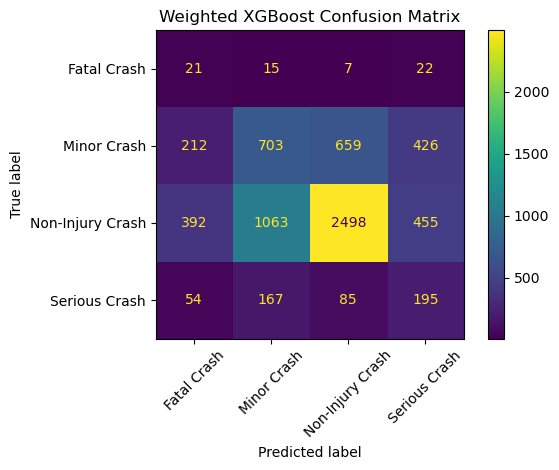

In [54]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    weighted_xgb_predictions,
    xticks_rotation=45
)

plt.title("Weighted XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

In [55]:
# Final comparison of all eight baseline models

all_model_predictions = {
    "Dummy Classifier": dummy_predictions,
    "Logistic Regression": logistic_predictions,
    "Balanced Logistic Regression": balanced_logistic_predictions,
    "Random Forest": rf_predictions,
    "Balanced Random Forest": balanced_rf_predictions,
    "Oversampled Logistic Regression": ros_logistic_predictions,
    "XGBoost": xgb_predictions,
    "Weighted XGBoost": weighted_xgb_predictions
}

final_baseline_results = pd.DataFrame([
    {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )
    }
    for model_name, predictions in all_model_predictions.items()
])

display(
    final_baseline_results
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

standard_scores = final_baseline_results.set_index("Model").loc["XGBoost"]
weighted_scores = final_baseline_results.set_index("Model").loc[
    "Weighted XGBoost"
]

weighted_report = classification_report(
    y_test,
    weighted_xgb_predictions,
    output_dict=True,
    zero_division=0
)

best_macro_f1_model = final_baseline_results.loc[
    final_baseline_results["Macro F1"].idxmax(), "Model"
]

print(
    "\nApplying balanced sample weights changed XGBoost performance "
    "on the seed-42 held-out test set."
)

print(
    f"Accuracy: {standard_scores['Accuracy']:.4f} → "
    f"{weighted_scores['Accuracy']:.4f}"
)
print(
    f"Balanced Accuracy: {standard_scores['Balanced Accuracy']:.4f} → "
    f"{weighted_scores['Balanced Accuracy']:.4f}"
)
print(
    f"Macro F1: {standard_scores['Macro F1']:.4f} → "
    f"{weighted_scores['Macro F1']:.4f}"
)

print(
    f"\nWeighted XGBoost Fatal recall: "
    f"{weighted_report['Fatal Crash']['recall']:.2%}"
)
print(
    f"Weighted XGBoost Serious recall: "
    f"{weighted_report['Serious Crash']['recall']:.2%}"
)
print(
    f"Weighted XGBoost Fatal precision: "
    f"{weighted_report['Fatal Crash']['precision']:.2%}"
)

print(f"\nHighest Macro F1 among the tested models: {best_macro_f1_model}")

print(
    "\nFor XGBoost on this split, balanced sample weights improved "
    "Macro F1, Balanced Accuracy and severe-class recall while "
    "reducing overall Accuracy. Fatal precision remained low. "
    "This single-split comparison does not establish statistical "
    "significance or consistency across other splits."
)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Weighted XGBoost,0.4900,0.4076,0.3272
1,Random Forest,0.6372,0.3094,0.3127
2,Balanced Logistic Regression,0.4498,0.4129,0.3065
3,Balanced Random Forest,0.6291,0.3042,0.3053
4,Oversampled Logistic Regression,0.4465,0.4089,0.3052
5,XGBoost,0.6703,0.3079,0.3034
6,Logistic Regression,0.6709,0.3012,0.2918
7,Dummy Classifier,0.6321,0.2500,0.1936



Applying balanced sample weights changed XGBoost performance on the seed-42 held-out test set.
Accuracy: 0.6703 → 0.4900
Balanced Accuracy: 0.3079 → 0.4076
Macro F1: 0.3034 → 0.3272

Weighted XGBoost Fatal recall: 32.31%
Weighted XGBoost Serious recall: 38.92%
Weighted XGBoost Fatal precision: 3.09%

Highest Macro F1 among the tested models: Weighted XGBoost

For XGBoost on this split, balanced sample weights improved Macro F1, Balanced Accuracy and severe-class recall while reducing overall Accuracy. Fatal precision remained low. This single-split comparison does not establish statistical significance or consistency across other splits.
